# Auxiliary-task transfer, part a of 2: aux_none, aux_k02345

**Question.** Can an UNRELATED auxiliary task that covers long instructions, late positions and zero-identity
inputs teach the positional behaviour needed for the main task's longer instructions? The main task's own long
instructions are never trained.

**Main task (all conditions).**
* S=7 with `<identity>` fillers, operations A/B/C (they move cells).
* Trained k ∈ {0,2,3,4,5}.
* Tests: singletons at every slot, k=6, k=7. The test set is the sampled one from notebook 23, record for record.

**Auxiliary task.**
* Value operations D: d → d+1 (mod 10) and E: d → 9−d. They change digits but never move a cell, so no D/E word
  equals any A/B/C composition.
* Same 7 slots, same `<identity>` fillers, same random placement.
* Every instruction starts with a task marker (`<main>` / `<aux>`).

| condition | auxiliary training k | per update (main / aux) |
|---|---|---|
| aux_none | — | 256 / 0 (baseline) |
| aux_k02345 | 0,2,3,4,5 | 192 / 64 (extra task, no extra length) |
| aux_k0234567 | 0,2,3,4,5,6,7 | 192 / 64 (with long and zero-identity auxiliary instructions) |
| aux_k01234567 | 0,1,2,…,7 | 192 / 64 (also single D / E) |

**Shared across conditions.** Transformer AR and the causal encoder, 20,000 updates, one initialization per
architecture. Checkpoint selection uses the main task only; evaluation uses the LAST checkpoint.

**This notebook = part a** (aux_none, aux_k02345). The other half is notebook 26b; run both at the same
time. **Send back `AuxTask_parta_Review.ipynb`.** After both finish, the optional last cell gives
`AuxTask_ALL_Review.ipynb`.


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 629eb4615517cde959e55c13ef0e36acba86baa5


In [2]:
# --- CONFIGURATION -------------------------------------------------------------------------------------------------
MODE = os.environ.get("DECOMP_MODE", "full")
SEED = 42
RUN_CONDITIONS = ['aux_none', 'aux_k02345']
ALL_CONDITIONS = ["aux_none", "aux_k02345", "aux_k0234567", "aux_k01234567"]
RUN_MODELS = ["transformer_ar", "causal_encoder"]
STEPS = 20000
EVAL_PLAN = {"n_single_grids": 1000, "n_seen_per_k": 5000, "n_long_per_k": 20000, "n_aux_per_k": 1000}
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
import pandas as pd
from IPython.display import display
pd.set_option("display.max_rows", 500); pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)
from decompositionality import auxtask as AX, auxtask_exp as AXE
_c = AXE.make_cfg(RUN_CONDITIONS[0], RESULTS_ROOT, MODE, RUN_MODELS, SEED, **({"optimizer_steps": STEPS} if MODE == "full" else {}))
print("resolved recipe:", _c.train.semantic_dict())
print("results ->", AXE.family_root(RESULTS_ROOT, MODE))


Mounted at /content/drive
resolved recipe: {'seed': 42, 'optimizer_steps': 20000, 'effective_batch_size': 256, 'lr': 0.0003, 'min_lr': 3e-05, 'weight_decay': 0.01, 'betas': [0.9, 0.95], 'warmup_steps': 250, 'grad_clip': 1.0, 'val_every': 250}
results -> /content/drive/MyDrive/decompositionality_results/aux_task_transfer_v1


In [3]:
# --- Train (20,000 updates) + LAST-checkpoint evaluation, sequentially (resumable) ----------------------------------
status = AXE.run_queue(RESULTS_ROOT, MODE, SEED, RUN_CONDITIONS, RUN_MODELS, EVAL_PLAN,
                       steps=STEPS if MODE == "full" else None, repo_dir=str(REPO_DIR), device=DEVICE)
display(status)


[aux_none] aux k=[] (0/update) | val 1500 (main only) | manifests bdf24c327a65

=== aux_none / transformer_ar ===
  microbatch probe: 256 fits
[transformer_ar] 10,707,865 params | device NVIDIA RTX PRO 6000 Blackwell Server Edition | dtype bf16 | microbatch 256 x accumulation 1 = 256
  [val @ 250] cell CE 1.6076 (best) | subset(160) exact 0.194 cell 0.371
  [val @ 500] cell CE 1.2125 (best) | subset(160) exact 0.212 cell 0.395
  step 650/20000 loss 1.0111 lr 3.00e-04 | 31.74 steps/s, 8125 ex/s | ETA 10.2 min
  [val @ 750] cell CE 0.9553 (best) | subset(160) exact 0.194 cell 0.423
  [val @ 1000] cell CE 0.6212 (best) | subset(160) exact 0.219 cell 0.509
  [val @ 1250] cell CE 0.4204 (best) | subset(160) exact 0.294 cell 0.598
  step 1275/20000 loss 0.3754 lr 2.98e-04 | 30.35 steps/s, 7771 ex/s | ETA 10.3 min
  [val @ 1500] cell CE 0.2932 (best) | subset(160) exact 0.306 cell 0.681
  [val @ 1750] cell CE 0.2161 (best) | subset(160) exact 0.381 cell 0.745
  step 1950/20000 loss 0.1459 lr 

,condition,model,trained,evaluated_last,records,complete
0,aux_none,transformer_ar,True,True,90000,True
1,aux_none,causal_encoder,True,True,90000,True
2,aux_k02345,transformer_ar,True,True,90000,True
3,aux_k02345,causal_encoder,True,True,90000,True


# Auxiliary-task transfer (seed 42; LAST checkpoint)
4/4 runs complete.

Main task: S=7, A/B/C, trained k ∈ {0,2,3,4,5}; held out: singletons (every slot), k=6, k=7. Auxiliary task: value operations D (d+1 mod 10) and E (9−d), never moving a cell, with the training k listed per condition.


### Run status


,condition,model,trained,evaluated_last,records,complete
0,aux_none,transformer_ar,True,True,90000,True
1,aux_none,causal_encoder,True,True,90000,True
2,aux_k02345,transformer_ar,True,True,90000,True
3,aux_k02345,causal_encoder,True,True,90000,True



### Main task (held out: singletons, k=6, k=7)


,condition,model,aux k,status,single A,single B,single C,singletons,main trained-k exact,main k=6,main k=7
0,aux_none,transformer_ar,[],available,0/7000,0/7000,0/7000,0/21000,1.0,0/20000 (0.000),2071/20000 (0.104)
1,aux_none,causal_encoder,[],available,7000/7000,7000/7000,7000/7000,21000/21000,1.0,19717/20000 (0.986),19057/20000 (0.953)
2,aux_k02345,transformer_ar,"[0, 2, 3, 4, 5]",available,0/7000,0/7000,0/7000,0/21000,1.0,0/20000 (0.000),1740/20000 (0.087)
3,aux_k02345,causal_encoder,"[0, 2, 3, 4, 5]",available,7000/7000,7000/7000,7000/7000,21000/21000,1.0,18976/20000 (0.949),5885/20000 (0.294)



### Auxiliary task accuracy by k


... (2 outputs left out)

I slot,condition,model,1,2,3,4,5,6,7
0,aux_k02345,causal_encoder,0.8986,0.9619,0.9867,1.0000,0.9822,0.9425,0.8681
1,aux_k02345,transformer_ar,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,aux_none,causal_encoder,0.9911,0.9993,0.9990,0.9997,0.9955,0.9779,0.9382
3,aux_none,transformer_ar,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000



### Main k=6 failures equal to 'drop the 5th operation'


,condition,model,k=6 failures,= drop op #5,share
0,aux_none,transformer_ar,20000,4736,0.237
1,aux_none,causal_encoder,283,0,0.000
2,aux_k02345,transformer_ar,20000,1428,0.071
3,aux_k02345,causal_encoder,1024,0,0.000



### Main-task held-out accuracy by condition


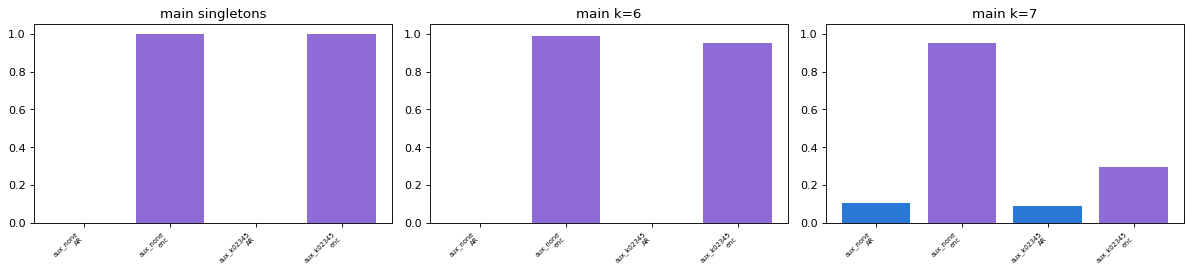

REVIEW FILE: /content/drive/MyDrive/decompositionality_results/aux_task_transfer_v1/report/seed_42_parta/AuxTask_parta_Review.ipynb
REVIEW FILE TO SEND BACK: /content/drive/MyDrive/decompositionality_results/aux_task_transfer_v1/report/seed_42_parta/AuxTask_parta_Review.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# --- Report for THIS half -------------------------------------------------------------------------------------------
rp = AXE.report(RESULTS_ROOT, MODE, SEED, RUN_CONDITIONS, out_name=f"seed_{SEED}_parta",
                review_name="AuxTask_parta_Review.ipynb")
print("REVIEW FILE TO SEND BACK:", rp)
if IN_COLAB:
    from google.colab import files
    files.download(str(rp))


# Auxiliary-task transfer (seed 42; LAST checkpoint)
4/8 runs complete.

Main task: S=7, A/B/C, trained k ∈ {0,2,3,4,5}; held out: singletons (every slot), k=6, k=7. Auxiliary task: value operations D (d+1 mod 10) and E (9−d), never moving a cell, with the training k listed per condition.


### Run status


,condition,model,trained,evaluated_last,records,complete
0,aux_none,transformer_ar,True,True,90000.0,True
1,aux_none,causal_encoder,True,True,90000.0,True
2,aux_k02345,transformer_ar,True,True,90000.0,True
3,aux_k02345,causal_encoder,True,True,90000.0,True
4,aux_k0234567,transformer_ar,False,False,NaN,False
5,aux_k0234567,causal_encoder,False,False,NaN,False
6,aux_k01234567,transformer_ar,False,False,NaN,False
7,aux_k01234567,causal_encoder,False,False,NaN,False



### Main task (held out: singletons, k=6, k=7)


,condition,model,aux k,status,single A,single B,single C,singletons,main trained-k exact,main k=6,main k=7
0,aux_none,transformer_ar,[],available,0/7000,0/7000,0/7000,0/21000,1.0,0/20000 (0.000),2071/20000 (0.104)
1,aux_none,causal_encoder,[],available,7000/7000,7000/7000,7000/7000,21000/21000,1.0,19717/20000 (0.986),19057/20000 (0.953)
2,aux_k02345,transformer_ar,"[0, 2, 3, 4, 5]",available,0/7000,0/7000,0/7000,0/21000,1.0,0/20000 (0.000),1740/20000 (0.087)
3,aux_k02345,causal_encoder,"[0, 2, 3, 4, 5]",available,7000/7000,7000/7000,7000/7000,21000/21000,1.0,18976/20000 (0.949),5885/20000 (0.294)
4,aux_k0234567,transformer_ar,NaN,not yet available,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,aux_k0234567,causal_encoder,NaN,not yet available,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,aux_k01234567,transformer_ar,NaN,not yet available,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,aux_k01234567,causal_encoder,NaN,not yet available,NaN,NaN,NaN,NaN,NaN,NaN,NaN



### Auxiliary task accuracy by k


... (2 outputs left out)

I slot,condition,model,1,2,3,4,5,6,7
0,aux_k02345,causal_encoder,0.8986,0.9619,0.9867,1.0000,0.9822,0.9425,0.8681
1,aux_k02345,transformer_ar,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,aux_none,causal_encoder,0.9911,0.9993,0.9990,0.9997,0.9955,0.9779,0.9382
3,aux_none,transformer_ar,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000



### Main k=6 failures equal to 'drop the 5th operation'


,condition,model,k=6 failures,= drop op #5,share
0,aux_none,transformer_ar,20000,4736,0.237
1,aux_none,causal_encoder,283,0,0.000
2,aux_k02345,transformer_ar,20000,1428,0.071
3,aux_k02345,causal_encoder,1024,0,0.000



### Main-task held-out accuracy by condition


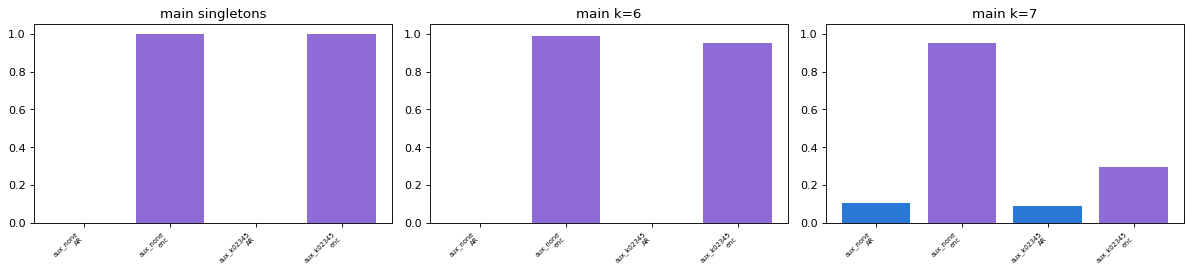

REVIEW FILE: /content/drive/MyDrive/decompositionality_results/aux_task_transfer_v1/report/seed_42_all/AuxTask_ALL_Review.ipynb
COMBINED REVIEW FILE: /content/drive/MyDrive/decompositionality_results/aux_task_transfer_v1/report/seed_42_all/AuxTask_ALL_Review.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
# --- OPTIONAL: combined report (run after BOTH 26a and 26b finished) ------------------------------------------------
rp_all = AXE.report(RESULTS_ROOT, MODE, SEED, ALL_CONDITIONS, out_name=f"seed_{SEED}_all", review_name="AuxTask_ALL_Review.ipynb")
print("COMBINED REVIEW FILE:", rp_all)
if IN_COLAB:
    from google.colab import files
    files.download(str(rp_all))
